In [ ]:
import kagglehub
path = kagglehub.dataset_download("kasikrit/att-database-of-faces")

100%|██████████| 3.61M/3.61M [00:00<00:00, 103MB/s]

Extracting files...


In [ ]:
# Import libraries

import os
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)

In [ ]:
# Locate and load images

# 'path' is the variable returned by kagglehub.dataset_download()
root = Path(path)

image_paths = sorted(
    p for p in root.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".pgm"
    and re.fullmatch(r"s\d+", p.parent.name, re.IGNORECASE)
)

if not image_paths:
    raise FileNotFoundError(
        f"No PGM images found under {root}. "
        "Inspect the downloaded folder structure."
    )

images = []
labels = []

for file in image_paths:
    with Image.open(file) as img:
        img = img.convert("L")
        images.append(np.asarray(img, dtype=np.uint8))
    labels.append(file.parent.name.lower())

images = np.stack(images)
labels = np.array(labels)

print("Image array shape:", images.shape)
print("Number of images:", len(images))
print("Number of identities:", len(np.unique(labels)))
print("Image dimensions:", images.shape[1:])
print("Unique images per identity:")
print(pd.Series(labels).value_counts().sort_index())

Image array shape: (400, 112, 92)
Number of images: 400
Number of identities: 40
Image dimensions: (112, 92)
Unique images per identity:
s1     10
s10    10
s11    10
s12    10
s13    10
s14    10
s15    10
s16    10
s17    10
s18    10
s19    10
s2     10
s20    10
s21    10
s22    10
s23    10
s24    10
s25    10
s26    10
s27    10
s28    10
s29    10
s3     10
s30    10
s31    10
s32    10
s33    10
s34    10
s35    10
s36    10
s37    10
s38    10
s39    10
s4     10
s40    10
s5     10
s6     10
s7     10
s8     10
s9     10
Name: count, dtype: int64


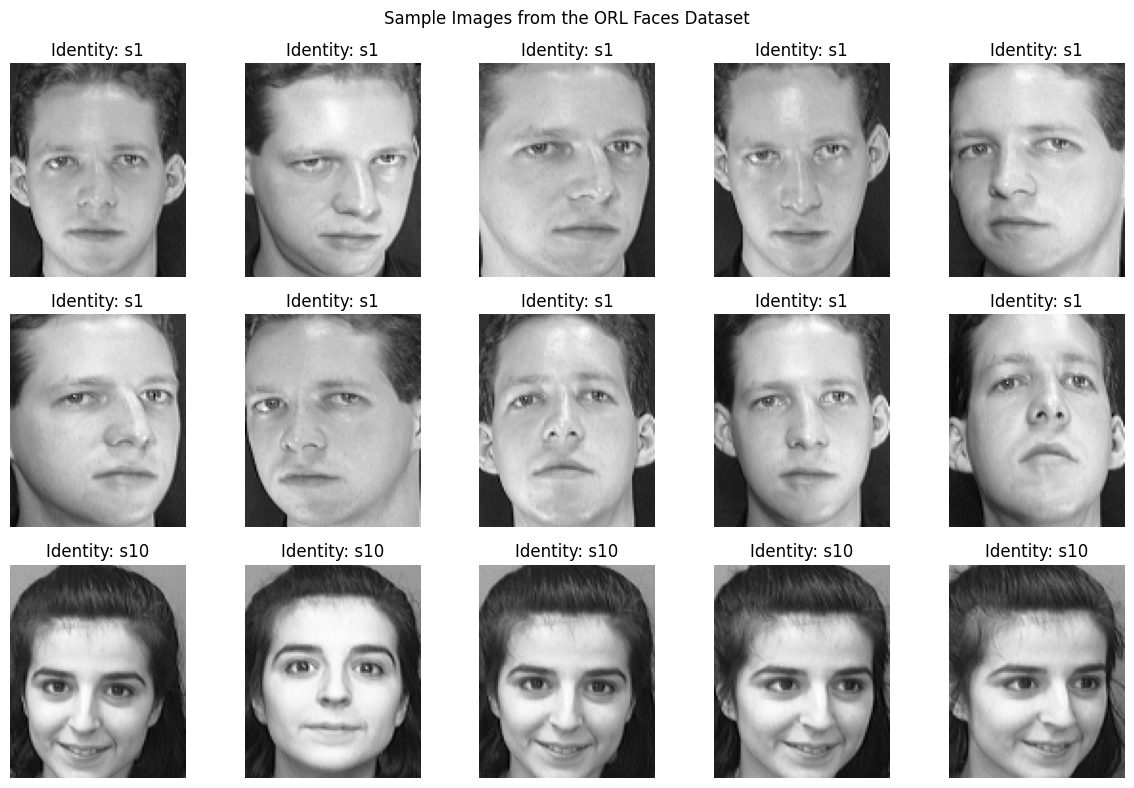

In [ ]:
# Display sample faces

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for ax, idx in zip(axes.ravel(), range(15)):
    ax.imshow(images[idx], cmap="gray")
    ax.set_title(f"Identity: {labels[idx]}")
    ax.axis("off")

plt.suptitle("Sample Images from the ORL Faces Dataset")
plt.tight_layout()
plt.show()

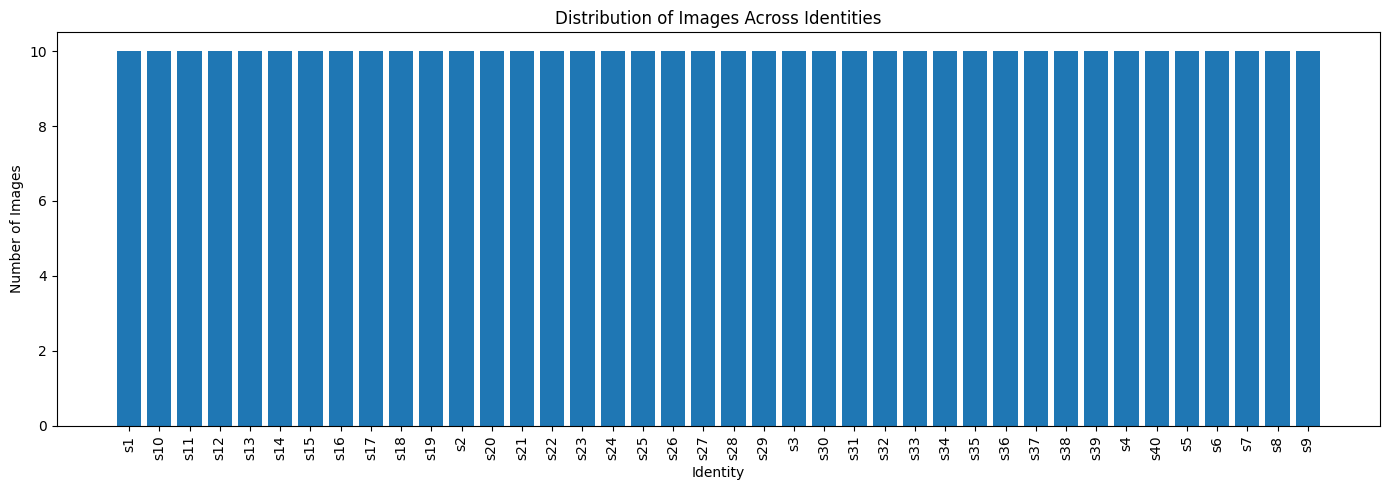

In [ ]:
# Images per identity

counts = pd.Series(labels).value_counts().sort_index()

plt.figure(figsize=(14, 5))
plt.bar(counts.index, counts.values)
plt.xlabel("Identity")
plt.ylabel("Number of Images")
plt.title("Distribution of Images Across Identities")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# Flatten and normalize

X = images.reshape(len(images), -1).astype(np.float32) / 255.0
y = labels

print("Feature matrix shape:", X.shape)
print("Features per image:", X.shape[1])
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Feature matrix shape: (400, 10304)
Features per image: 10304
Minimum pixel value: 0.0
Maximum pixel value: 0.9843137


In [ ]:
# Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Original feature dimensions:", X_train.shape[1])

Training images: 280
Testing images: 120
Original feature dimensions: 10304


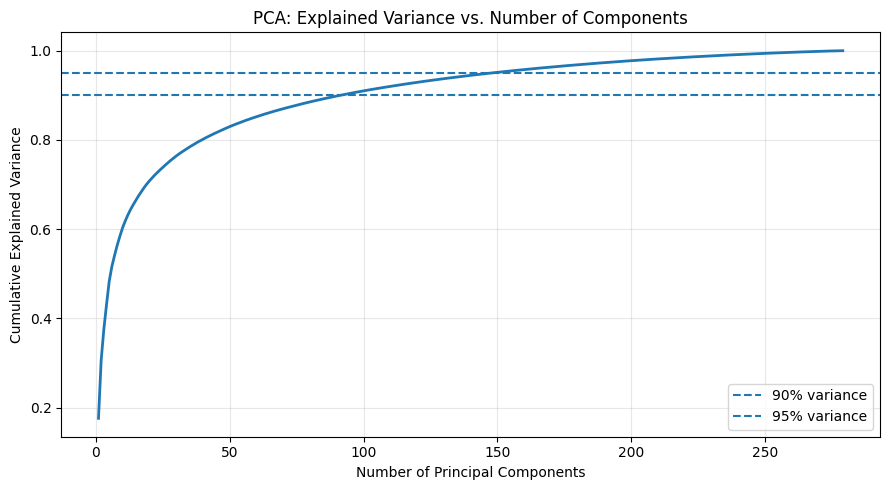

Components needed for 80% variance: 40
Components needed for 90% variance: 92
Components needed for 95% variance: 148


In [ ]:
# Fit PCA on training data

max_components = min(X_train.shape[0] - 1, X_train.shape[1])

pca_full = PCA(
    n_components=max_components,
    svd_solver="randomized",
    random_state=42
)

pca_full.fit(X_train)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Explained Variance vs. Number of Components")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for threshold in [0.80, 0.90, 0.95]:
    k = np.searchsorted(cumulative_variance, threshold) + 1
    print(f"Components needed for {threshold:.0%} variance: {k}")

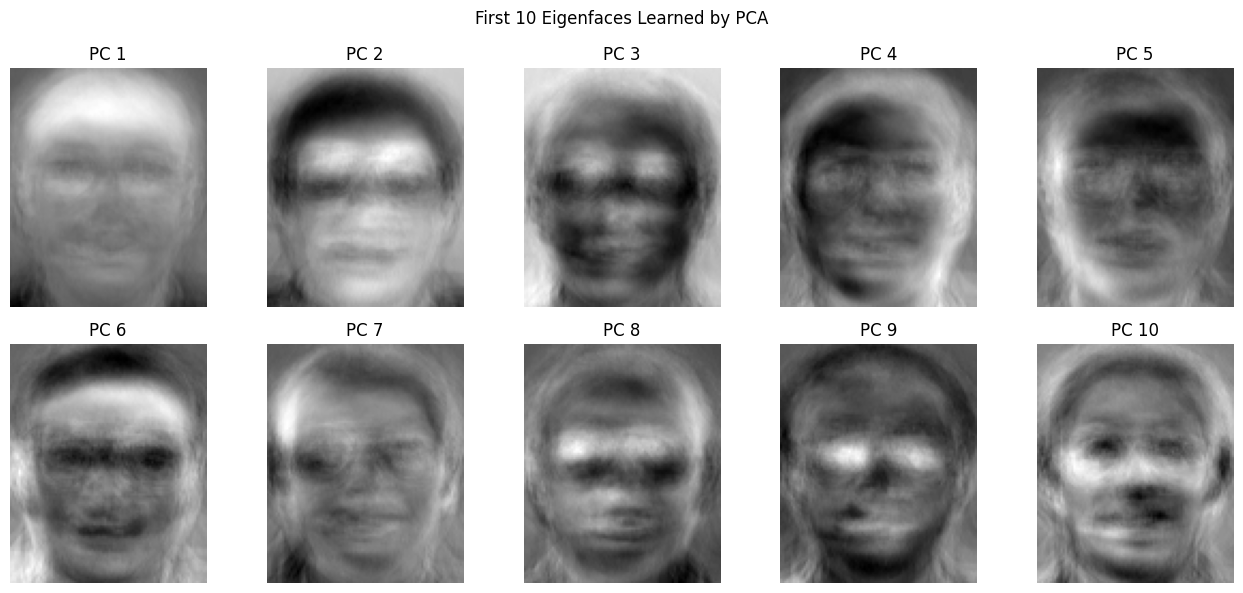

In [ ]:
# Visualize the first 10 Eigenfaces

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i, ax in enumerate(axes.ravel()):
    eigenface = pca_full.components_[i].reshape(images.shape[1:])
    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"PC {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 Eigenfaces Learned by PCA")
plt.tight_layout()
plt.show()

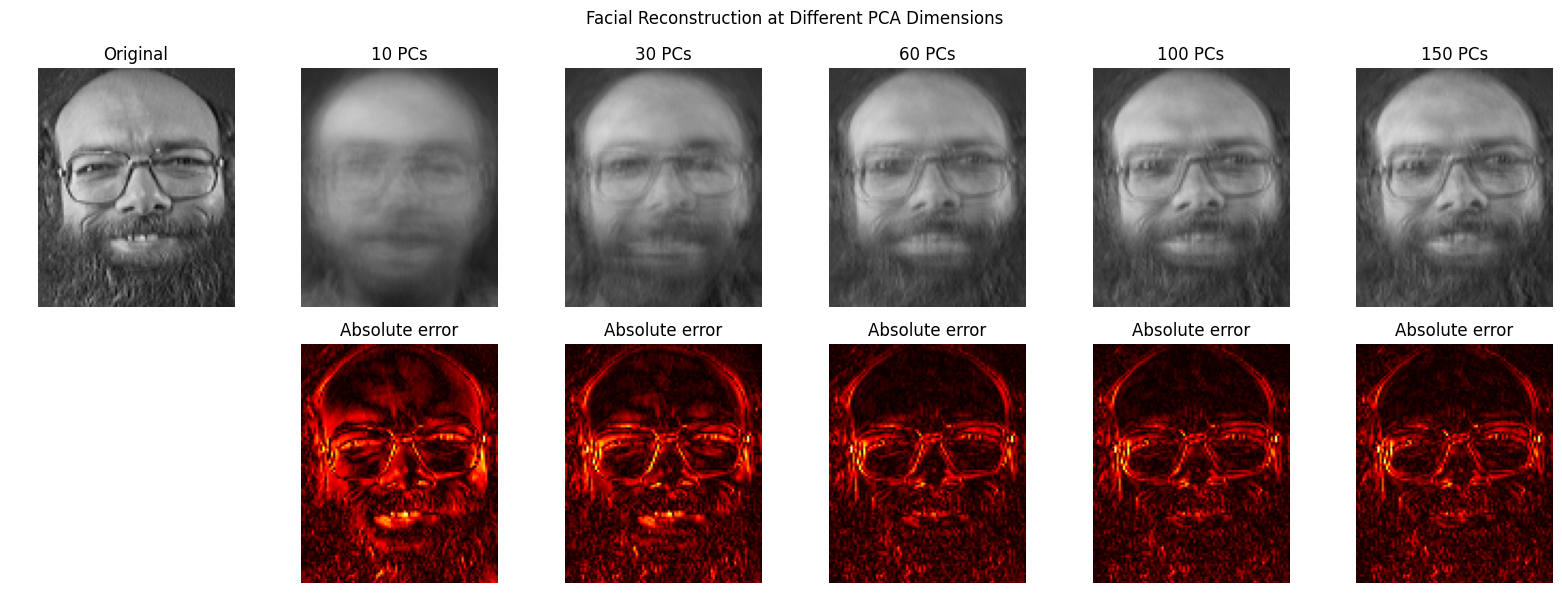

In [ ]:
# Compare original and reconstructed faces

component_choices = [10, 30, 60, 100, 150]
sample_index = 0

original = X_test[sample_index].reshape(images.shape[1:])

fig, axes = plt.subplots(
    2, len(component_choices) + 1,
    figsize=(16, 6)
)

axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")
axes[1, 0].axis("off")

for col, k in enumerate(component_choices, start=1):
    pca = PCA(
        n_components=k,
        svd_solver="randomized",
        random_state=42
    )
    pca.fit(X_train)

    compressed = pca.transform(X_test[sample_index:sample_index + 1])
    reconstructed = pca.inverse_transform(compressed)[0]
    reconstructed = np.clip(reconstructed, 0, 1)

    axes[0, col].imshow(
        reconstructed.reshape(images.shape[1:]),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, col].set_title(f"{k} PCs")
    axes[0, col].axis("off")

    difference = np.abs(
        original - reconstructed.reshape(images.shape[1:])
    )
    axes[1, col].imshow(difference, cmap="hot")
    axes[1, col].set_title("Absolute error")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Reconstruction")
axes[1, 0].set_ylabel("Error map")
plt.suptitle("Facial Reconstruction at Different PCA Dimensions")
plt.tight_layout()
plt.show()

In [ ]:
# Evaluate PCA component counts

component_choices = [
    k for k in [10, 20, 30, 40, 60, 80, 100, 150, 200]
    if k <= max_components
]

# Baseline: identification using all raw pixel features
baseline = KNeighborsClassifier(n_neighbors=1)

start = time.perf_counter()
baseline.fit(X_train, y_train)
baseline_fit_time = time.perf_counter() - start

start = time.perf_counter()
baseline_predictions = baseline.predict(X_test)
baseline_test_time = time.perf_counter() - start

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

results = []

for k in component_choices:
    pca = PCA(
        n_components=k,
        svd_solver="randomized",
        random_state=42
    )

    # Fit PCA only on the training set
    start = time.perf_counter()
    X_train_pca = pca.fit_transform(X_train)
    pca_fit_time = time.perf_counter() - start

    # Transform the held-out test set
    X_test_pca = pca.transform(X_test)

    # Reconstruction error on the test set
    X_reconstructed = pca.inverse_transform(X_test_pca)
    mse = np.mean((X_test - X_reconstructed) ** 2)

    # Identification on compressed features
    classifier = KNeighborsClassifier(n_neighbors=1)
    classifier.fit(X_train_pca, y_train)

    start = time.perf_counter()
    predictions = classifier.predict(X_test_pca)
    compressed_test_time = time.perf_counter() - start

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Components": k,
        "Explained Variance (%)":
            100 * np.sum(pca.explained_variance_ratio_),
        "Reconstruction MSE": mse,
        "Identification Accuracy (%)": 100 * accuracy,
        "Feature Reduction (%)": 100 * (1 - k / X.shape[1]),
        "Raw Test Time (ms)": 1000 * baseline_test_time,
        "PCA Test Time (ms)": 1000 * compressed_test_time,
        "PCA Fit Time (s)": pca_fit_time
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

print(f"Raw-pixel identification accuracy: "
      f"{baseline_accuracy * 100:.2f}%")
print(f"Raw-pixel test prediction time: "
      f"{baseline_test_time * 1000:.3f} ms")

,Components,Explained Variance (%),Reconstruction MSE,Identification Accuracy (%),Feature Reduction (%),Raw Test Time (ms),PCA Test Time (ms),PCA Fit Time (s)
0,10,60.320400,0.0100,95.8333,99.9030,134.1971,11.6624,0.5040
1,20,70.803200,0.0081,96.6667,99.8059,134.1971,4.5462,0.7221
2,30,76.353600,0.0072,97.5000,99.7089,134.1971,1.5940,0.5358
3,40,80.106300,0.0065,97.5000,99.6118,134.1971,1.6140,0.6630
4,60,85.152603,0.0058,98.3333,99.4177,134.1971,3.7436,0.9937
5,80,88.451401,0.0054,98.3333,99.2236,134.1971,1.9214,1.9960
6,100,90.923203,0.0051,98.3333,99.0295,134.1971,1.8531,1.3608
7,150,95.077698,0.0046,98.3333,98.5443,134.1971,2.3505,1.8532
8,200,97.714302,0.0043,98.3333,98.0590,134.1971,6.5396,2.4704


Raw-pixel identification accuracy: 98.33%
Raw-pixel test prediction time: 134.197 ms


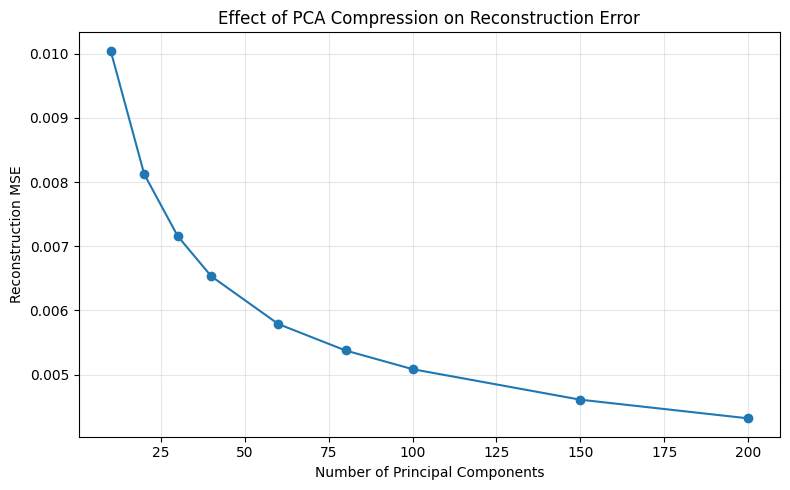

In [ ]:
# Reconstruction error vs. component count

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["Components"],
    results_df["Reconstruction MSE"],
    marker="o"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Reconstruction MSE")
plt.title("Effect of PCA Compression on Reconstruction Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

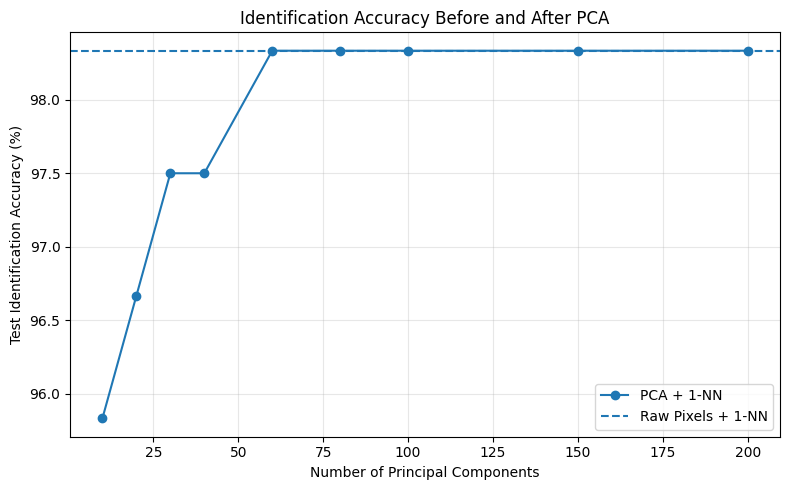

In [ ]:
# Identification accuracy vs. component count

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["Components"],
    results_df["Identification Accuracy (%)"],
    marker="o",
    label="PCA + 1-NN"
)
plt.axhline(
    baseline_accuracy * 100,
    linestyle="--",
    label="Raw Pixels + 1-NN"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Test Identification Accuracy (%)")
plt.title("Identification Accuracy Before and After PCA")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

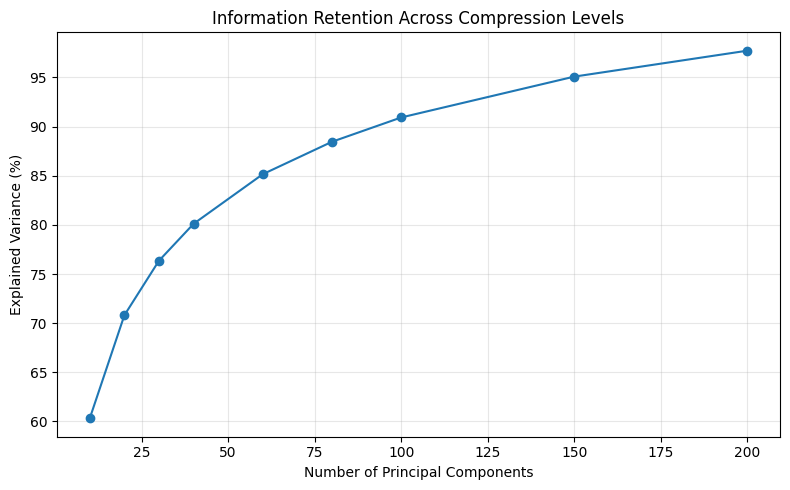

In [ ]:
# Explained variance vs. component count

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["Components"],
    results_df["Explained Variance (%)"],
    marker="o"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Information Retention Across Compression Levels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

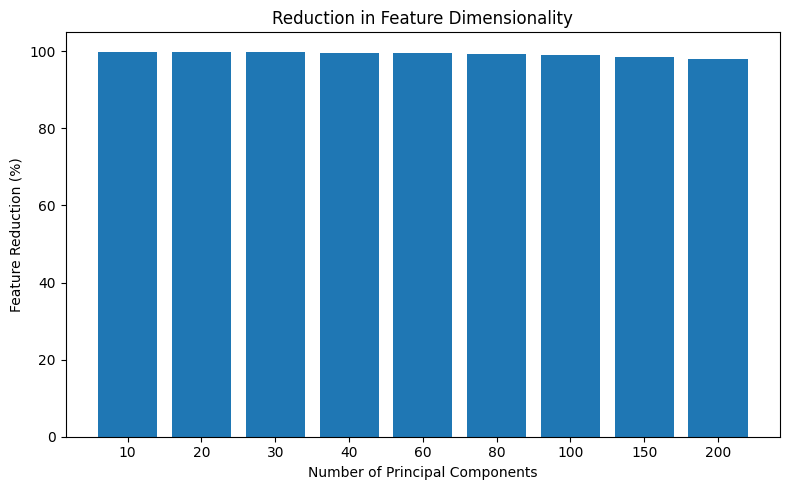

In [ ]:
# Feature dimensionality reduction

plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Components"].astype(str),
    results_df["Feature Reduction (%)"]
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Feature Reduction (%)")
plt.title("Reduction in Feature Dimensionality")
plt.tight_layout()
plt.show()

,Components,Raw Prediction (ms),Compressed Prediction (ms),PCA + Identification (ms),Speedup (classifier only),Speedup (end-to-end)
0,10,134.1971,8.6763,19.0666,15.4671,7.0383
1,20,134.1971,3.0476,36.7026,44.0335,3.6563
2,30,134.1971,1.5476,14.8460,86.7155,9.0393
3,40,134.1971,2.2117,15.9668,60.6747,8.4048
4,60,134.1971,3.0102,15.6315,44.5813,8.5850
5,80,134.1971,1.4552,8.8423,92.2159,15.1767
6,100,134.1971,1.5299,9.9481,87.7161,13.4897
7,150,134.1971,2.6796,14.8755,50.0816,9.0213
8,200,134.1971,2.0146,15.9505,66.6133,8.4134


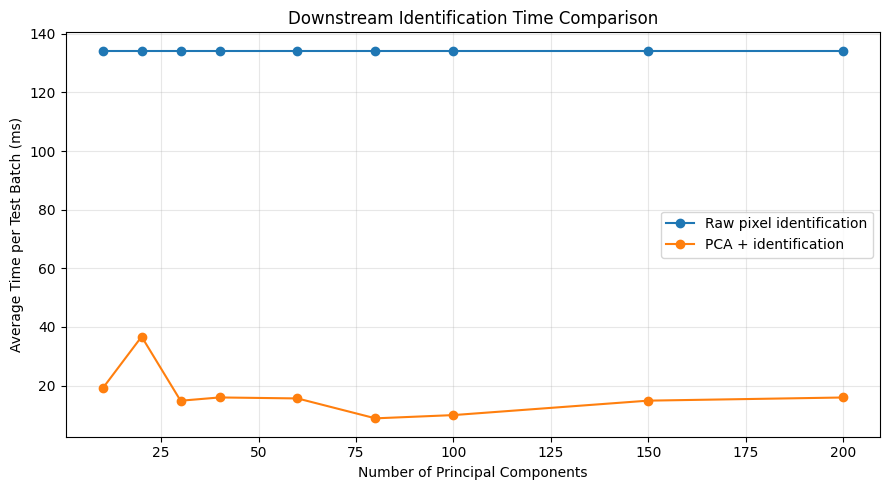

In [ ]:
# End-to-end test-time comparison

timing_rows = []

for k in component_choices:
    pca = PCA(
        n_components=k,
        svd_solver="randomized",
        random_state=42
    )

    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    clf = KNeighborsClassifier(n_neighbors=1)
    clf.fit(X_train_pca, y_train)

    # Repeat prediction to reduce timer noise
    repeats = 30

    start = time.perf_counter()
    for _ in range(repeats):
        clf.predict(X_test_pca)
    compressed_time = (time.perf_counter() - start) / repeats

    # Include PCA transformation for each incoming batch
    start = time.perf_counter()
    for _ in range(repeats):
        query_features = pca.transform(X_test)
        clf.predict(query_features)
    end_to_end_time = (time.perf_counter() - start) / repeats

    timing_rows.append({
        "Components": k,
        "Raw Prediction (ms)": baseline_test_time * 1000,
        "Compressed Prediction (ms)": compressed_time * 1000,
        "PCA + Identification (ms)": end_to_end_time * 1000,
        "Speedup (classifier only)":
            baseline_test_time / compressed_time,
        "Speedup (end-to-end)":
            baseline_test_time / end_to_end_time
    })

timing_df = pd.DataFrame(timing_rows)
display(timing_df.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    timing_df["Components"],
    timing_df["Raw Prediction (ms)"],
    marker="o",
    label="Raw pixel identification"
)
plt.plot(
    timing_df["Components"],
    timing_df["PCA + Identification (ms)"],
    marker="o",
    label="PCA + identification"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Average Time per Test Batch (ms)")
plt.title("Downstream Identification Time Comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

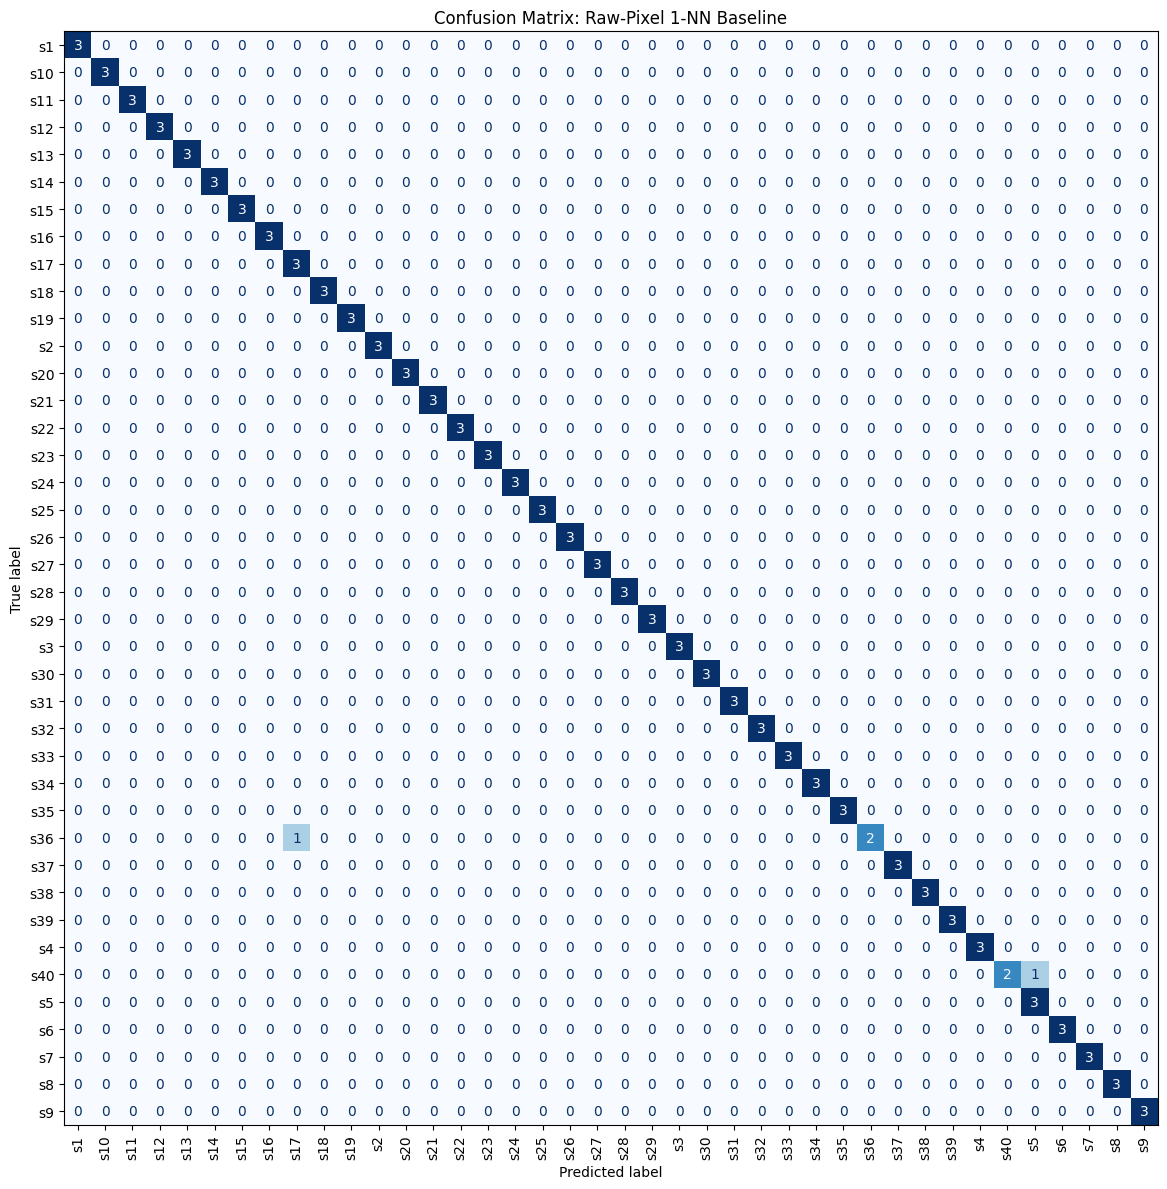

In [ ]:
# Confusion matrix for the raw-pixel baseline

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    labels=sorted(np.unique(y)),
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix: Raw-Pixel 1-NN Baseline")
plt.gcf().set_size_inches(12, 12)
plt.tight_layout()
plt.show()

## Results and Discussion

PCA was applied to the AT&T ORL Faces Dataset to reduce the dimensionality of facial images from 10,304 pixel features to a lower-dimensional representation.

The experiments evaluated multiple principal component counts using cumulative explained variance, reconstruction mean squared error, identification accuracy, dimensionality reduction, and computational time.

As the number of principal components increased, the model was expected to retain more variance and reconstruct facial images more accurately. However, retaining more components also increases the dimensionality of the compressed representation.

The raw-pixel nearest-neighbor classifier was used as the baseline for evaluating identification performance. The PCA-based classifier was then compared against this baseline using the same train/test split and classification method.

**Best configuration:** [Insert selected component count]

**Explained variance retained:** [Insert measured value]

**Reconstruction MSE:** [Insert measured value]

**Identification accuracy:** [Insert measured value]

**Feature dimensionality reduction:** [Insert measured percentage]

**End-to-end test-time comparison:** [Insert measured result]

## Conclusion

The experiment demonstrates how PCA can compress facial images into a lower-dimensional subspace while retaining information useful for reconstruction and identification. The final component count was selected by balancing reconstruction quality, retained variance, identification accuracy, and computational cost.

The results also demonstrate that dimensionality reduction and computational speedup are related but distinct outcomes. The benefit of PCA must be established through measured performance rather than assumed from the reduction in feature count alone.

## Limitations

The ORL dataset contains a relatively small number of low-resolution, mostly frontal grayscale images. Consequently, the results may not generalize to high-resolution photographs or unconstrained real-world facial recognition. Future work could evaluate PCA on larger datasets and investigate its sensitivity to pose, illumination, and image quality.